In [1]:
import os
import numpy as np
from matplotlib import pyplot as plt, colormaps
import tifffile

In [2]:
basedir = "/home/swim/shared/Si_project/260707_BCAT_tif_file"
os.listdir(basedir)

['f_410_1_obj_phase_roi_Niter100.tiff',
 'f_410_2_obj_phase_roi_Niter100.tiff',
 'f_410_3_obj_phase_roi_Niter100.tiff',
 'f_410_4_obj_phase_roi_Niter100.tiff',
 'f_420_1_obj_phase_roi_Niter120.tiff',
 'f_420_2_obj_phase_roi_Niter120.tiff',
 'f_420_3_obj_phase_roi_Niter120.tiff',
 'f_420_4_obj_phase_roi_Niter120.tiff',
 'f_430_1_obj_phase_roi_Niter80.tiff',
 'f_430_2_obj_phase_roi_Niter80.tiff',
 'f_430_3_obj_phase_roi_Niter80.tiff',
 'f_430_4_obj_phase_roi_Niter80.tiff',
 'f_450_1_obj_phase_roi_Niter90.tiff',
 'f_450_2_obj_phase_roi_Niter90.tiff',
 'f_450_3_obj_phase_roi_Niter90.tiff',
 'f_450_4_obj_phase_roi_Niter90.tiff',
 'f_471_1_obj_phase_roi_Niter50.tiff',
 'f_471_2_obj_phase_roi_Niter50.tiff',
 'f_471_3_obj_phase_roi_Niter50.tiff',
 'f_471_4_obj_phase_roi_Niter50.tiff',
 'f_471_5_obj_phase_roi_Niter230.tiff',
 'f_471_6_obj_phase_roi_Niter230.tiff',
 'f_471_7_obj_phase_roi_Niter230.tiff',
 'f_472_1_obj_phase_roi_Niter50.tiff',
 'f_472_2_obj_phase_roi_Niter50.tiff',
 'f_472_3_obj_

In [5]:
tiff = 'f_430_2_obj_phase_roi_Niter80.tiff'
image = tifffile.imread(os.path.join(basedir, tiff))

roi_A = 92
A_per_px = roi_A / image.shape[0]  # A/pixel
Si_distance_px = 1.358 / A_per_px


print(f"Shape : {image.shape}")
print(f"Dtype : {image.dtype}")
print(f"H × W : {image.shape[0]} × {image.shape[1]}")
print(f"Pixel Size : {A_per_px:.2f} A/px")

# fig, ax = plt.subplots(figsize=(7, 7))
# ax.imshow(image[image.shape[0] // 2], cmap='gray')
# ax.set_title(f"Raw Image  ({image.shape[0]} × {image.shape[1]} px)")
# ax.axis('on')   # 픽셀 좌표 눈금 표시
# plt.tight_layout()
# plt.show()

Shape : (30, 379, 379)
Dtype : uint8
H × W : 30 × 379
Pixel Size : 3.07 A/px


(np.float64(-0.5), np.float64(378.5), np.float64(378.5), np.float64(-0.5))

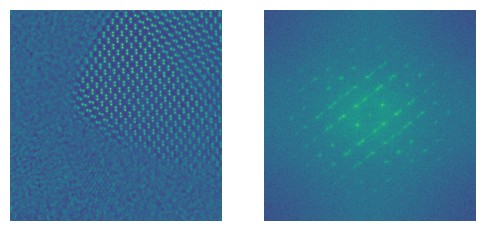

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
ax1, ax2 = axs

layer = image[3]

ax1.imshow(layer)
ax1.axis('off')

ax2.imshow(np.log1p(abs(np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(layer))))))
ax2.axis('off')

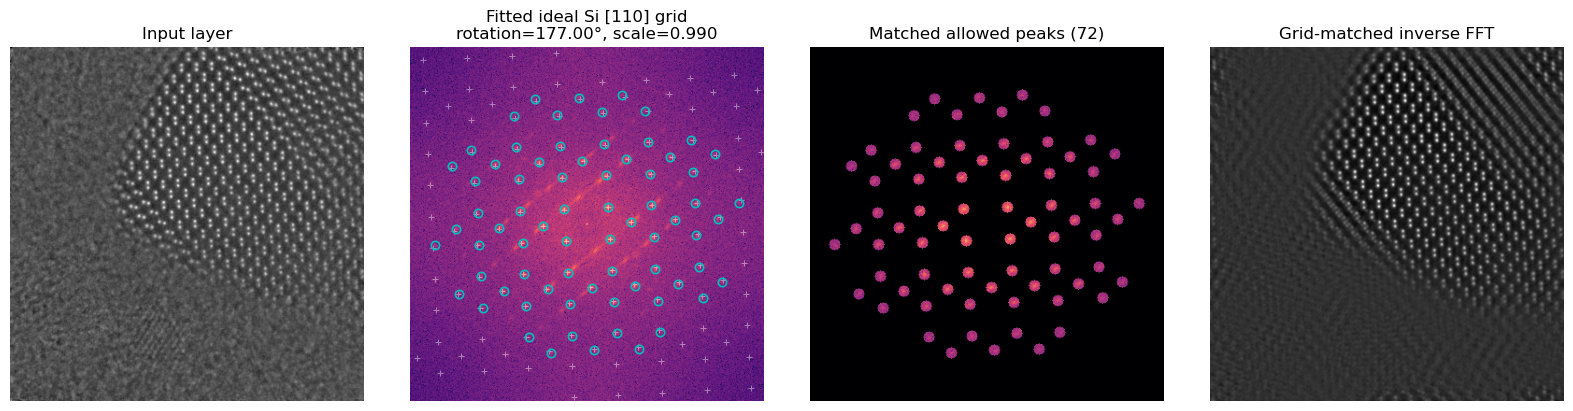

In [11]:
# Match the FFT to an ideal diamond-cubic Si [110] diffraction grid.
# For zone axis [110], h + k = 0.  The supplied fcc/diamond extinction
# rules leave: (h, -h, l), with h and l both odd, or both even with l = 4n.
layer = image[3].astype(float)
height, width = layer.shape
A_per_px_xy = roi_A / height
d_004_A = 1.358  # given above; for Si, d_004 = a / 4
a_si_A = 4 * d_004_A

fft_shifted = np.fft.fftshift(np.fft.fft2(layer))
spectrum = np.log1p(np.abs(fft_shifted))
centre_y, centre_x = (np.asarray(layer.shape) - 1) / 2
yy, xx = np.ogrid[:height, :width]
radius_px = np.hypot(xx - centre_x, yy - centre_y)

# Detect candidate Bragg maxima once.  Keep only the strongest candidates so
# the rotation/scale fit is driven by diffraction peaks rather than background.
neighbourhood = 3
local_maximum = spectrum.copy()
for dy in range(-neighbourhood, neighbourhood + 1):
    for dx in range(-neighbourhood, neighbourhood + 1):
        local_maximum = np.maximum(local_maximum, np.roll(np.roll(spectrum, dy, 0), dx, 1))
candidate_pixels = np.argwhere((spectrum == local_maximum) & (radius_px > 8))
candidate_strength = spectrum[candidate_pixels[:, 0], candidate_pixels[:, 1]]
strongest = np.argsort(candidate_strength)[-min(600, len(candidate_pixels)):]
candidate_pixels = candidate_pixels[strongest]
candidate_strength = candidate_strength[strongest]

# Build all allowed reciprocal-lattice points in the [110] zone.  Coordinates
# are expressed along [1 -1 0] (horizontal) and [001] (vertical).
grid_hkls, grid_xy = [], []
base_scale_px = width * A_per_px_xy / a_si_A  # pixels per reciprocal 1/a
for h in range(-12, 13):
    for l in range(-12, 13):
        if h == 0 and l == 0:
            continue
        all_odd = (h % 2 != 0) and (l % 2 != 0)
        diamond_even = (h % 2 == 0) and (l % 2 == 0) and (l % 4 == 0)
        if all_odd or diamond_even:
            grid_hkls.append((h, -h, l))
            grid_xy.append((np.sqrt(2) * h * base_scale_px, l * base_scale_px))
grid_hkls = np.asarray(grid_hkls)
grid_xy = np.asarray(grid_xy)

match_tolerance_px = 4.5
def projected_grid(angle_deg, scale_factor):
    angle = np.deg2rad(angle_deg)
    rotation = np.array([[np.cos(angle), -np.sin(angle)],
                         [np.sin(angle),  np.cos(angle)]])
    xy = scale_factor * grid_xy @ rotation.T
    pixels = np.column_stack((centre_y + xy[:, 1], centre_x + xy[:, 0]))
    valid = ((pixels[:, 0] >= 4) & (pixels[:, 0] < height - 4)
             & (pixels[:, 1] >= 4) & (pixels[:, 1] < width - 4))
    return grid_hkls[valid], pixels[valid]

def grid_score(angle_deg, scale_factor):
    _, targets = projected_grid(angle_deg, scale_factor)
    distance2 = ((targets[:, None, :] - candidate_pixels[None, :, :]) ** 2).sum(axis=2)
    nearest = np.argmin(distance2, axis=1)
    # Gaussian distance weighting rewards agreement with many allowed spots.
    return np.sum(candidate_strength[nearest] * np.exp(-distance2[np.arange(len(targets)), nearest]
                                                         / (2 * match_tolerance_px ** 2)))

# Fit detector rotation and a small scale correction to the measured FFT.
best_score, best_angle, best_scale = -np.inf, None, None
for scale in np.linspace(0.94, 1.06, 7):
    for angle in np.arange(0, 180, 2):
        score = grid_score(angle, scale)
        if score > best_score:
            best_score, best_angle, best_scale = score, angle, scale
for scale in np.linspace(best_scale - 0.015, best_scale + 0.015, 7):
    for angle in np.linspace(best_angle - 2, best_angle + 2, 17):
        score = grid_score(angle, scale)
        if score > best_score:
            best_score, best_angle, best_scale = score, angle, scale

# Retain only observed candidate peaks that are close to allowed, fitted-grid sites.
fitted_hkls, fitted_pixels = projected_grid(best_angle, best_scale)
distance2 = ((fitted_pixels[:, None, :] - candidate_pixels[None, :, :]) ** 2).sum(axis=2)
nearest = np.argmin(distance2, axis=1)
matched = []
used_candidates = set()
for hkl, distance, candidate_index in zip(fitted_hkls, distance2[np.arange(len(fitted_pixels)), nearest], nearest):
    if distance <= match_tolerance_px ** 2 and int(candidate_index) not in used_candidates:
        matched.append((hkl, candidate_pixels[candidate_index]))
        used_candidates.add(int(candidate_index))
if not matched:
    raise RuntimeError('The fitted Si [110] grid did not match any FFT candidates.')

mask_radius_px = 6
si110_grid_mask = np.zeros(layer.shape, dtype=bool)
for _, (y, x) in matched:
    si110_grid_mask |= (xx - x) ** 2 + (yy - y) ** 2 <= mask_radius_px ** 2
si110_grid_fft = fft_shifted * si110_grid_mask
si110_grid_image = np.fft.ifft2(np.fft.ifftshift(si110_grid_fft)).real

fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
axes[0].imshow(layer, cmap='gray'); axes[0].set_title('Input layer')
axes[1].imshow(spectrum, cmap='magma')
axes[1].set_title(f'Fitted ideal Si [110] grid\nrotation={best_angle:.2f}°, scale={best_scale:.3f}')
axes[2].imshow(np.log1p(np.abs(si110_grid_fft)), cmap='magma', vmin=0, vmax=spectrum.max())
axes[2].set_title(f'Matched allowed peaks ({len(matched)})')
axes[3].imshow(si110_grid_image, cmap='gray'); axes[3].set_title('Grid-matched inverse FFT')
for hkl, pixel in zip(fitted_hkls, fitted_pixels):
    axes[1].plot(pixel[1], pixel[0], 'w+', ms=4, mew=0.7, alpha=0.45)
for hkl, (y, x) in matched:
    axes[1].plot(x, y, 'co', ms=6, mfc='none', mew=1.2)
for ax in axes:
    ax.axis('off')
plt.show()

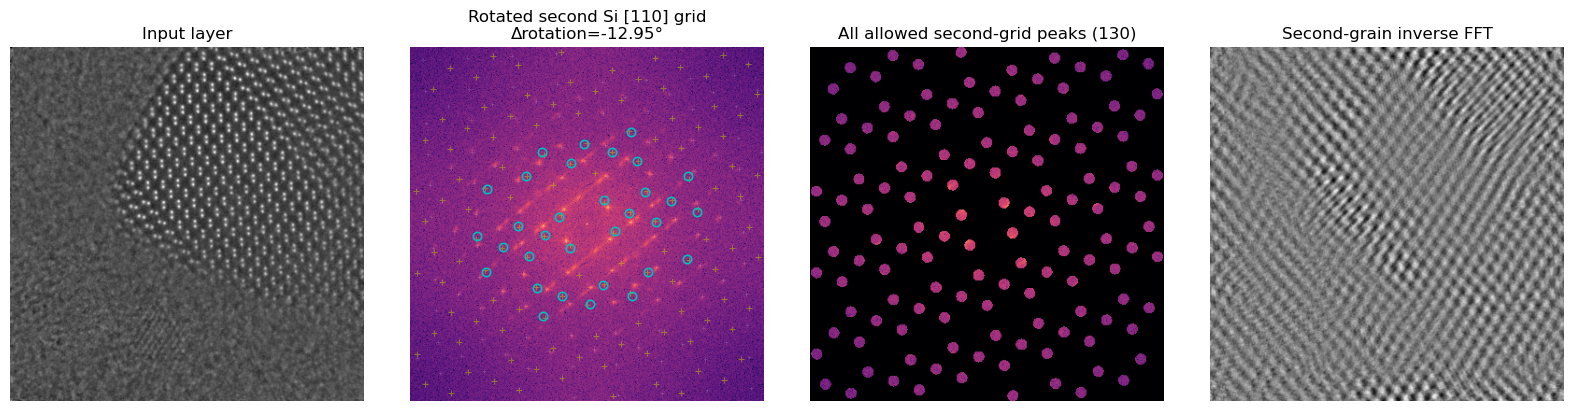

In [12]:
# Second-dominant Si [110] grain. Run the preceding grid-fit cell first.
# Keep the first grain's calibrated grid scale fixed; search only its rotation.
# Remove every candidate close to the first orientation's full ideal grid.
first_grid_pixels = fitted_pixels
distance2_to_first = ((candidate_pixels[:, None, :] - first_grid_pixels[None, :, :]) ** 2).sum(axis=2)
keep_residual = distance2_to_first.min(axis=1) > (2 * match_tolerance_px) ** 2
second_candidate_pixels = candidate_pixels[keep_residual]
second_candidate_strength = candidate_strength[keep_residual]
if len(second_candidate_pixels) == 0:
    raise RuntimeError('No FFT candidates remain after excluding the first grid.')

second_scale = best_scale
def second_grid_score(angle_deg):
    _, targets = projected_grid(angle_deg, second_scale)
    distance2 = ((targets[:, None, :] - second_candidate_pixels[None, :, :]) ** 2).sum(axis=2)
    nearest = np.argmin(distance2, axis=1)
    nearest_distance2 = distance2[np.arange(len(targets)), nearest]
    matches = nearest_distance2 <= match_tolerance_px ** 2
    return np.sum(second_candidate_strength[nearest[matches]]
                  * (1 - nearest_distance2[matches] / match_tolerance_px ** 2))

# Coarse-to-fine rotation-only fit of the strongest remaining Si [110] grid.
second_score, second_angle = -np.inf, None
for angle in np.arange(0, 180, 1):
    score = second_grid_score(angle)
    if score > second_score:
        second_score, second_angle = score, angle
for angle in np.linspace(second_angle - 1, second_angle + 1, 41):
    score = second_grid_score(angle)
    if score > second_score:
        second_score, second_angle = score, angle

second_hkls, second_grid_pixels = projected_grid(second_angle, second_scale)
relative_rotation = (second_angle - best_angle + 90) % 180 - 90
distance2 = ((second_grid_pixels[:, None, :] - second_candidate_pixels[None, :, :]) ** 2).sum(axis=2)
nearest = np.argmin(distance2, axis=1)
second_matched, used_candidates = [], set()
for hkl, distance, candidate_index in zip(second_hkls, distance2[np.arange(len(second_grid_pixels)), nearest], nearest):
    if distance <= match_tolerance_px ** 2 and int(candidate_index) not in used_candidates:
        second_matched.append((hkl, second_candidate_pixels[candidate_index]))
        used_candidates.add(int(candidate_index))
if not second_matched:
    raise RuntimeError('No second Si [110] grid peaks matched the residual FFT.')

# Pass every allowed peak in the fitted second-grain grid, including weak sites
# that were not strong enough to be used as orientation-matching candidates.
second_mask = np.zeros(layer.shape, dtype=bool)
for y, x in second_grid_pixels:
    second_mask |= (xx - x) ** 2 + (yy - y) ** 2 <= mask_radius_px ** 2
second_fft = fft_shifted * second_mask
second_grain_image = np.fft.ifft2(np.fft.ifftshift(second_fft)).real

fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
axes[0].imshow(layer, cmap='gray'); axes[0].set_title('Input layer')
axes[1].imshow(spectrum, cmap='magma')
axes[1].set_title(f'Rotated second Si [110] grid\nΔrotation={relative_rotation:.2f}°')
axes[2].imshow(np.log1p(np.abs(second_fft)), cmap='magma', vmin=0, vmax=spectrum.max())
axes[2].set_title(f'All allowed second-grid peaks ({len(second_grid_pixels)})')
axes[3].imshow(second_grain_image, cmap='gray'); axes[3].set_title('Second-grain inverse FFT')
for pixel in first_grid_pixels:
    axes[1].plot(pixel[1], pixel[0], 'w+', ms=3, mew=0.5, alpha=0.18)
for pixel in second_grid_pixels:
    axes[1].plot(pixel[1], pixel[0], 'y+', ms=4, mew=0.8, alpha=0.5)
for _, (y, x) in second_matched:
    axes[1].plot(x, y, 'co', ms=6, mfc='none', mew=1.2)
for ax in axes:
    ax.axis('off')
plt.show()

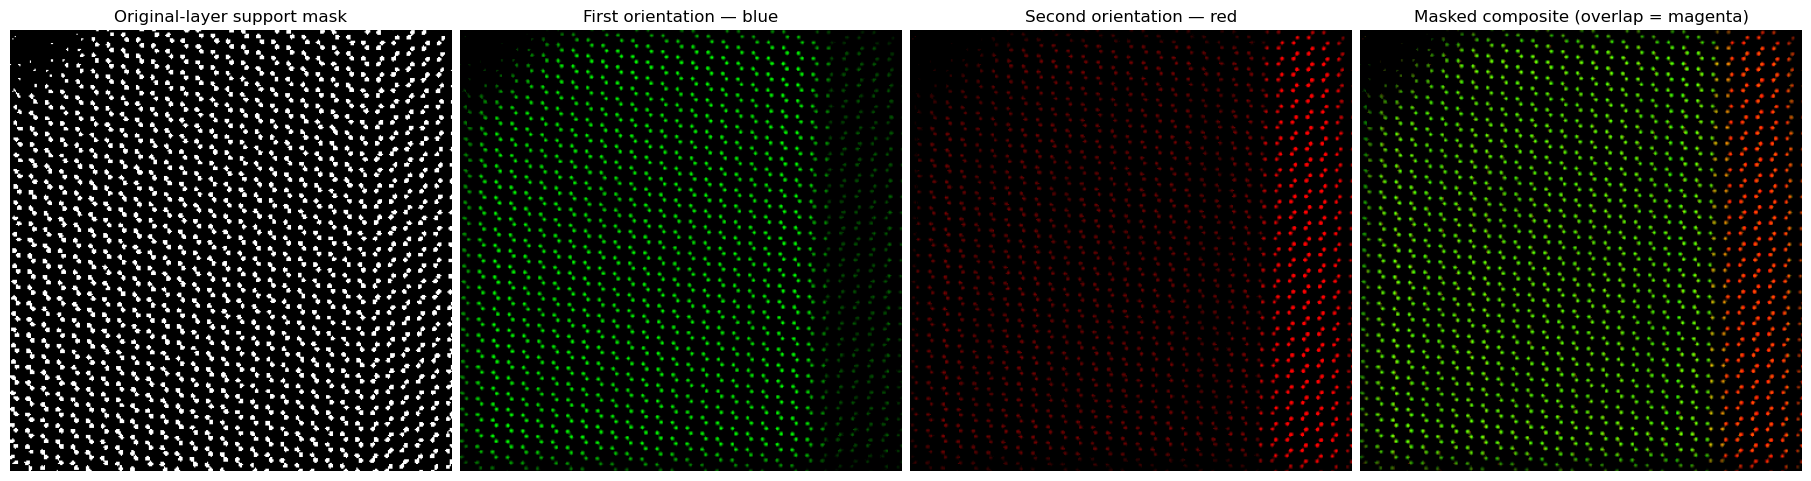

In [22]:
# Composite of the two fitted Si [110] grain reconstructions.
# Run the first-grid and second-grid cells before this cell.
def display_strength(filtered_image):
    amplitude = np.abs(filtered_image)
    low, high = np.percentile(amplitude, (1, 99.5))
    if high == low:
        return np.zeros_like(amplitude)
    return np.clip((amplitude - low) / (high - low), 0, 1)

first_blue = display_strength(si110_grid_image)
second_red = display_strength(second_grain_image)

# Use the original layer as a real-space support mask.  Pixels below this
# contrast level cannot receive Fourier-filtered color.
mask_low, mask_high = np.percentile(layer, (5, 95))
support_threshold = 0.5  # increase to reject more low-signal pixels
if mask_high == mask_low:
    original_mask = np.ones(layer.shape, dtype=bool)
else:
    original_support = np.clip((layer - mask_low) / (mask_high - mask_low), 0, 1)
    original_mask = original_support >= support_threshold

composite = np.zeros((*layer.shape, 3))
composite[..., 0] = second_red       # second orientation: red
composite[..., 1] = first_blue       # first orientation: blue
composite *= original_mask[..., None]

first_rgb = np.zeros_like(composite)
first_rgb[..., 1] = first_blue
first_rgb *= original_mask[..., None]
second_rgb = np.zeros_like(composite)
second_rgb[..., 0] = second_red
second_rgb *= original_mask[..., None]

fig, axes = plt.subplots(1, 4, figsize=(18, 5), constrained_layout=True)
axes[0].imshow(original_mask, cmap='gray'); axes[0].set_title('Original-layer support mask')
axes[1].imshow(first_rgb); axes[1].set_title('First orientation — blue')
axes[2].imshow(second_rgb); axes[2].set_title('Second orientation — red')
axes[3].imshow(composite); axes[3].set_title('Masked composite (overlap = magenta)')
for ax in axes:
    ax.axis('off')
plt.show()

Saved (32, 379, 379, 3) RGB stack to /home/swim/sandbox/silicon-grain-boundaries/colored.tiff


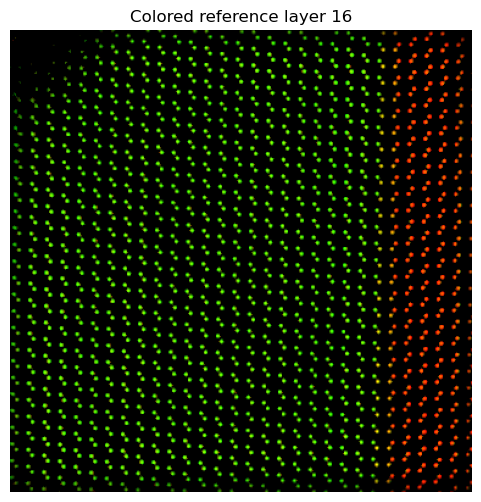

In [24]:
# Color the complete TIFF stack using the two orientations fitted on the reference layer.
# Run the first-grid and second-grid cells before this cell.
volume = image.astype(float)

# Fixed reciprocal-space masks from the reference layer are applied to every TIFF layer.
fft_volume = np.fft.fftshift(np.fft.fft2(volume, axes=(-2, -1)), axes=(-2, -1))
first_volume = np.fft.ifft2(
    np.fft.ifftshift(fft_volume * si110_grid_mask[None, :, :], axes=(-2, -1)), axes=(-2, -1)
).real
second_volume = np.fft.ifft2(
    np.fft.ifftshift(fft_volume * second_mask[None, :, :], axes=(-2, -1)), axes=(-2, -1)
).real

def normalize_volume(filtered_volume):
    amplitude = np.abs(filtered_volume)
    low, high = np.percentile(amplitude, (1, 99.5))
    if high == low:
        return np.zeros_like(amplitude)
    return np.clip((amplitude - low) / (high - low), 0, 1)

first_blue_volume = normalize_volume(first_volume)
second_red_volume = normalize_volume(second_volume)

# Build an original-image support mask per layer to suppress Fourier ringing.
stack_support_threshold = globals().get('support_threshold', 0.5)
support_volume = np.zeros(volume.shape, dtype=bool)
for index, original_layer in enumerate(volume):
    low, high = np.percentile(original_layer, (5, 95))
    if high == low:
        support_volume[index] = True
    else:
        scaled = np.clip((original_layer - low) / (high - low), 0, 1)
        support_volume[index] = scaled >= stack_support_threshold

colored_stack = np.zeros((*volume.shape, 3), dtype=np.uint8)
colored_stack[..., 0] = np.round(255 * second_red_volume * support_volume).astype(np.uint8)  # second: red
colored_stack[..., 1] = np.round(255 * first_blue_volume * support_volume).astype(np.uint8)   # first: blue

output_path = os.path.abspath('colored.tiff')
tifffile.imwrite(output_path, colored_stack, photometric='rgb', metadata={'axes': 'ZYXS'})
print(f'Saved {colored_stack.shape} RGB stack to {output_path}')

reference_index = image.shape[0] // 2
plt.figure(figsize=(6, 6))
plt.imshow(colored_stack[reference_index])
plt.title(f'Colored reference layer {reference_index}')
plt.axis('off')
plt.show()

Saved (32, 379, 379, 3) RGBA stack to /home/swim/sandbox/silicon-grain-boundaries/colored_alpha.tiff


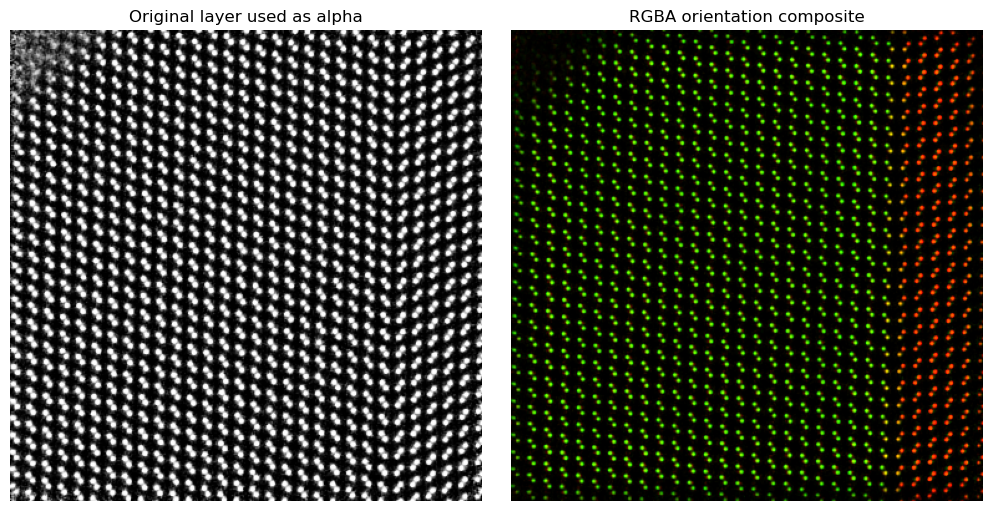

In [70]:
# RGBA version: use the original TIFF intensity as continuous alpha, not a cutoff mask.
# Run the two orientation-filter cells first.  Output: ./colored_alpha.tiff
volume = image.astype(float)
fft_volume = np.fft.fftshift(np.fft.fft2(volume, axes=(-2, -1)), axes=(-2, -1))
first_volume = np.fft.ifft2(
    np.fft.ifftshift(fft_volume * si110_grid_mask[None, :, :], axes=(-2, -1)), axes=(-2, -1)
).real
second_volume = np.fft.ifft2(
    np.fft.ifftshift(fft_volume * second_mask[None, :, :], axes=(-2, -1)), axes=(-2, -1)
).real

def normalize_for_display(values, percentiles=(1, 99.5)):
    low, high = np.percentile(values, percentiles)
    if high == low:
        return np.zeros_like(values)
    return np.clip((values - low) / (high - low), 0, 1)

# RGB encodes filtered orientation strength; alpha continuously follows original intensity.
first_blue_volume = normalize_for_display(np.abs(first_volume))
second_red_volume = normalize_for_display(np.abs(second_volume))
original_alpha = beta.cdf(normalize_for_display(volume), 3, 8)

colored_alpha_stack = np.zeros((*volume.shape, 3), dtype=np.uint8)
colored_alpha_stack[..., 0] = np.round(255 * (second_red_volume * (original_alpha))).astype(np.uint8)  # second: red
colored_alpha_stack[..., 1] = np.round(255 * (first_blue_volume * (original_alpha))).astype(np.uint8)   # first: blue
# colored_alpha_stack[..., 2] = np.ones_like(original_alpha) * 255
# colored_alpha_stack[..., 3] = np.round(255 * (original_alpha)).astype(np.uint8)       # original: alpha

output_path = os.path.abspath('colored_alpha.tiff')
tifffile.imwrite(
    output_path, colored_alpha_stack, photometric='rgb', extrasamples='unassalpha',
    metadata={'axes': 'ZYXS'},
)
print(f'Saved {colored_alpha_stack.shape} RGBA stack to {output_path}')

reference_index = image.shape[0] // 2
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
axes[0].imshow(original_alpha[reference_index], cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Original layer used as alpha')
axes[1].imshow(colored_alpha_stack[reference_index])
axes[1].set_title('RGBA orientation composite')
for ax in axes:
    ax.axis('off')
plt.show()

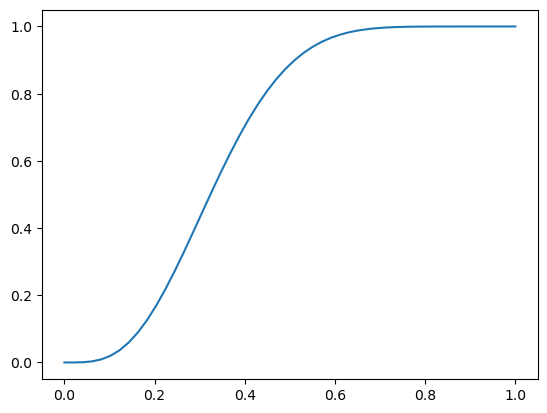

In [69]:
from scipy.stats import beta

x = np.linspace(0, 1)

plt.plot(x, beta.cdf(x, 4, 8))